# 01 Trends: growth before and after 2019

Put all data on 2020 tracts, then measure growth before and after 2019.

**Inputs**
- `data/processed/acs_tract.csv`
- `data/processed/jobs_tract.csv`
- `data/processed/decennial_units_tract.csv`
- `data/processed/tracts_2020.gpkg`
- `data/raw/boundaries/TAB2010_TAB2020_ST42.zip`

**Output (the tool reads this)**
- `data/processed/trends_tract.csv  (GEOID, growth_before, growth_after, trend_change, plus one column per measure)`
- `data/processed/tract_panel.csv` (all years on 2020 tracts, used by notebook 04)

Run `python musa5500/get_data.py` first.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
from common import RAW, OUT, ACS_YEARS

FIG = ROOT / "musa5500" / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## Load

- Check row counts and blanks

In [2]:
acs = pd.read_csv(OUT / "acs_tract.csv", dtype={"GEOID": str})
jobs = pd.read_csv(OUT / "jobs_tract.csv", dtype={"GEOID": str})
dec = pd.read_csv(OUT / "decennial_units_tract.csv", dtype={"GEOID": str})
tracts = gpd.read_file(OUT / "tracts_2020.gpkg")
print("tracts 2020:", len(tracts))
print(acs.groupby("acs_year").size())
print(jobs.groupby("year").size())
print(dec.groupby("year").size())
acs.isna().groupby(acs.acs_year).sum()[["median_rent", "median_value", "median_income"]]

tracts 2020: 3445
acs_year
2014    3218
2019    3218
2024    3446
dtype: int64
year
2010    3445
2014    3446
2019    3445
2024    3445
dtype: int64
year
2010    3218
2020    3446
dtype: int64


,median_rent,median_value,median_income
acs_year,,,
2014,72,50,34
2019,91,57,39
2024,185,95,69


## Crosswalk 2010 tracts to 2020 tracts

- Read the block crosswalk (pipe-delimited inside the zip)
- Weight = AREALAND_INT / AREALAND_2010
- Counts: sum weighted values into 2020 tracts
- Medians: take the 2010 tract with the biggest overlap
- Land area is a rough stand-in for where people live. It is the method in the plan. Block housing counts would be better but are not in this file

In [3]:
xw = pd.read_csv(RAW / "boundaries" / "TAB2010_TAB2020_ST42.zip", sep="|", dtype=str)
xw = xw[(xw.STATE_2010 == "42") & (xw.STATE_2020 == "42")].copy()
xw["tr10"] = xw.STATE_2010 + xw.COUNTY_2010 + xw.TRACT_2010
xw["tr20"] = xw.STATE_2020 + xw.COUNTY_2020 + xw.TRACT_2020
xw["land"] = xw.AREALAND_INT.astype(float)

pairs = xw.groupby(["tr10", "tr20"], as_index=False).land.sum()
land10 = pairs.groupby("tr10").land.transform("sum")
pairs["w"] = np.where(land10 > 0, pairs.land / land10, 0)
# Tracts that are all water: give the whole weight to one 2020 tract
water_only = land10 == 0
pairs.loc[water_only, "w"] = 1 / pairs[water_only].groupby("tr10").tr20.transform("size")
pairs = pairs[pairs.w > 0]

# For medians: the 2010 tract with the biggest land overlap
main10 = pairs.sort_values("land", ascending=False).drop_duplicates("tr20")[["tr20", "tr10"]]
print("2010 tracts:", pairs.tr10.nunique(), " 2020 tracts:", pairs.tr20.nunique())
print("weights sum to 1 per 2010 tract:", np.allclose(pairs.groupby("tr10").w.sum(), 1))
pairs.head()

2010 tracts: 3218  2020 tracts: 3446
weights sum to 1 per 2010 tract: True


,tr10,tr20,land,w
0,42001030101,42001030101,54729573.0,1.000000
2,42001030102,42001030103,18036255.0,0.264726
3,42001030102,42001030104,50095458.0,0.735274
4,42001030200,42001030101,47045.0,0.000388
5,42001030200,42001030200,121067675.0,0.999612


In [4]:
def to_2020(df, counts, medians):
    """Move a table on 2010 tracts (GEOID) to 2020 tracts."""
    m = pairs.merge(df, left_on="tr10", right_on="GEOID", how="inner")
    c = m[counts].multiply(m.w, axis=0).groupby(m.tr20).sum()
    med = main10.merge(df[["GEOID"] + medians], left_on="tr10", right_on="GEOID", how="left")
    med = med.set_index("tr20")[medians]
    out = c.join(med, how="outer").rename_axis("GEOID").reset_index()
    return out


COUNTS = ["pop", "housing_units", "vacant_units", "occupied_units", "renter_units", "single_family_detached"]
MEDIANS = ["median_rent", "median_value", "median_income"]

acs20 = {}
for y in [2014, 2019]:
    a = acs[acs.acs_year == y]
    acs20[y] = to_2020(a, COUNTS, MEDIANS)
    print(y, "pop before", int(a["pop"].sum()), "after", int(acs20[y]["pop"].sum()))
acs20[2024] = acs[acs.acs_year == 2024][["GEOID"] + COUNTS + MEDIANS].copy()

d10 = to_2020(dec[dec.year == 2010][["GEOID", "housing_units"]], ["housing_units"], [])
d20 = dec[dec.year == 2020][["GEOID", "housing_units"]]
print("decennial units 2010:", int(dec[dec.year == 2010].housing_units.sum()), "after crosswalk:", int(d10.housing_units.sum()))

2014 pop before 12758729 after 12758729
2019 pop before 12791530 after 12791530
decennial units 2010: 5567315 after crosswalk: 5567315


## Inflation to 2024 dollars

- CPI-U: 2014 = 236.736, 2019 = 255.657, 2024 = 313.689

In [5]:
CPI = {2014: 236.736, 2019: 255.657, 2024: 313.689}
for y, a in acs20.items():
    for c in MEDIANS:
        a[c] = a[c] * CPI[2024] / CPI[y]
pd.DataFrame({y: a[MEDIANS].median() for y, a in acs20.items()}).round(0)

,2014,2019,2024
median_rent,1087.0,1125.0,1149.0
median_value,202734.0,200490.0,230200.0
median_income,69013.0,73639.0,74844.0


## Growth before and after 2019

- Yearly rate = (end / start) ** (1 / years) - 1
- Before: ACS 2014 -> 2019, jobs 2010 -> 2019
- After: ACS 2019 -> 2024, jobs 2019 -> 2024
- trend_change = after - before
- Small bases make wild rates. A rate is blank if the start is under 200 people, 100 homes, or 50 jobs
- Headline columns (growth_before, growth_after, trend_change) use population. The other measures have their own columns

In [6]:
panel = tracts[["GEOID"]].copy()
for y, a in acs20.items():
    panel = panel.merge(a.add_suffix(f"_{y}").rename(columns={f"GEOID_{y}": "GEOID"}), on="GEOID", how="left")
jw = jobs.pivot_table(index="GEOID", columns="year", values=["jobs_here", "workers_living_here"], aggfunc="sum")
jw.columns = [f"{v}_{y}" for v, y in jw.columns]
panel = panel.merge(jw.reset_index(), on="GEOID", how="left")
panel = panel.merge(d10.rename(columns={"housing_units": "dec_units_2010"}), on="GEOID", how="left")
panel = panel.merge(d20.rename(columns={"housing_units": "dec_units_2020"}), on="GEOID", how="left")
panel["county"] = panel.GEOID.str[:5]
print(panel.shape)


def rate(start, end, years, min_start):
    r = (end / start) ** (1 / years) - 1
    return r.where((start >= min_start) & (end > 0))


MEASURES = {
    # name: (column prefix, before years, after years, min start)
    "pop": ("pop", (2014, 2019), (2019, 2024), 200),
    "units": ("housing_units", (2014, 2019), (2019, 2024), 100),
    "jobs": ("jobs_here", (2010, 2019), (2019, 2024), 50),
    "rent": ("median_rent", (2014, 2019), (2019, 2024), 1),
}
trends = panel[["GEOID"]].copy()
for m, (col, b, a, mn) in MEASURES.items():
    trends[f"{m}_growth_before"] = rate(panel[f"{col}_{b[0]}"], panel[f"{col}_{b[1]}"], b[1] - b[0], mn)
    trends[f"{m}_growth_after"] = rate(panel[f"{col}_{a[0]}"], panel[f"{col}_{a[1]}"], a[1] - a[0], mn)
    trends[f"{m}_change"] = trends[f"{m}_growth_after"] - trends[f"{m}_growth_before"]
trends["growth_before"] = trends.pop_growth_before
trends["growth_after"] = trends.pop_growth_after
trends["trend_change"] = trends.pop_change
(trends.drop(columns="GEOID").describe().T[["count", "25%", "50%", "75%"]] * [1, 100, 100, 100]).round(2)

(3445, 39)


,count,25%,50%,75%
pop_growth_before,3414.0,-0.91,-0.05,0.91
pop_growth_after,3407.0,-1.12,0.18,1.67
pop_change,3407.0,-1.54,0.29,2.15
units_growth_before,3395.0,-0.35,0.30,1.05
units_growth_after,3386.0,-1.07,0.22,1.66
units_change,3385.0,-1.68,-0.07,1.62
jobs_growth_before,3378.0,-1.48,0.88,3.39
jobs_growth_after,3411.0,-2.34,0.00,2.50
jobs_change,3370.0,-4.49,-0.95,2.67
rent_growth_before,3324.0,-0.97,0.76,2.43


### Statewide totals and medians

- Statewide growth from summed counts (not the median tract)

In [7]:
def cagr(a, b, yrs):
    return (b / a) ** (1 / yrs) - 1


tot = pd.DataFrame({
    "before": [cagr(panel.pop_2014.sum(), panel.pop_2019.sum(), 5),
               cagr(panel.housing_units_2014.sum(), panel.housing_units_2019.sum(), 5),
               cagr(panel.jobs_here_2010.sum(), panel.jobs_here_2019.sum(), 9)],
    "after": [cagr(panel.pop_2019.sum(), panel.pop_2024.sum(), 5),
              cagr(panel.housing_units_2019.sum(), panel.housing_units_2024.sum(), 5),
              cagr(panel.jobs_here_2019.sum(), panel.jobs_here_2024.sum(), 5)],
}, index=["pop", "units", "jobs"])
tot.loc["rent (median tract, real)"] = [trends.rent_growth_before.median(), trends.rent_growth_after.median()]
tot["change"] = tot.after - tot.before
print((tot * 100).round(2))

share = pd.DataFrame({m: [(trends[f"{m}_change"] > 0).mean(), trends[f"{m}_change"].notna().sum()]
                      for m in MEASURES}, index=["share sped up", "tracts with data"]).T
share

                           before  after  change
pop                          0.05   0.35    0.30
units                        0.41   0.39   -0.01
jobs                         0.95   0.31   -0.64
rent (median tract, real)    0.76   0.41   -0.35


,share sped up,tracts with data
pop,0.542525,3407.0
units,0.479536,3385.0
jobs,0.420029,3370.0
rent,0.434543,3214.0


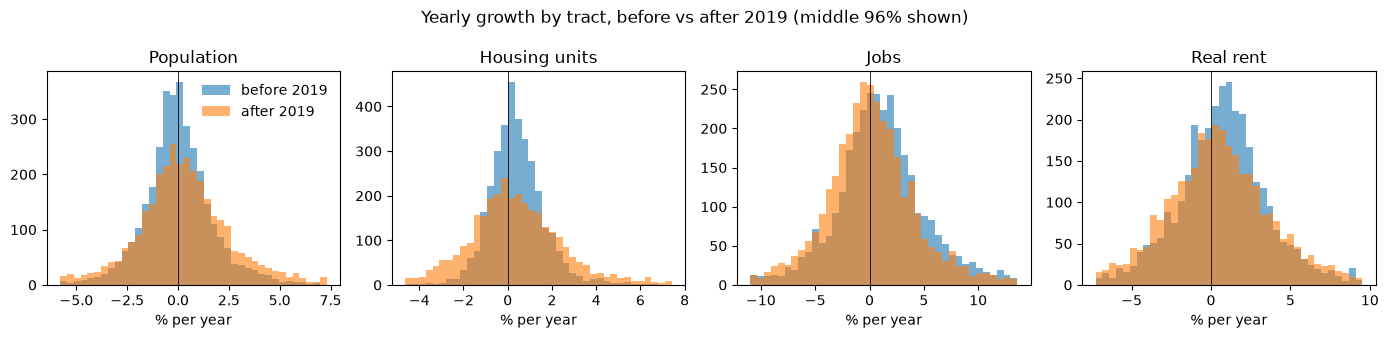

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, m in zip(axes, MEASURES):
    b, a = trends[f"{m}_growth_before"] * 100, trends[f"{m}_growth_after"] * 100
    lo, hi = np.nanpercentile(pd.concat([b, a]), [2, 98])
    bins = np.linspace(lo, hi, 40)
    ax.hist(b.dropna(), bins=bins, alpha=0.6, label="before 2019")
    ax.hist(a.dropna(), bins=bins, alpha=0.6, label="after 2019")
    ax.axvline(0, color="k", lw=0.6)
    ax.set_title({"pop": "Population", "units": "Housing units", "jobs": "Jobs", "rent": "Real rent"}[m])
    ax.set_xlabel("% per year")
axes[0].legend(frameon=False)
fig.suptitle("Yearly growth by tract, before vs after 2019 (middle 96% shown)")
fig.tight_layout()
fig.savefig(FIG / "01_growth_hist.png", dpi=150)

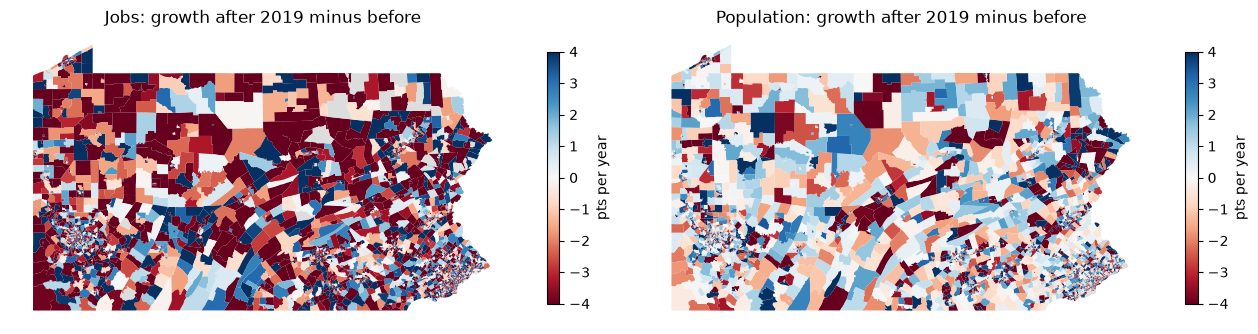

In [9]:
g = tracts.merge(trends, on="GEOID").to_crs(3857)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, m, t in zip(axes, ["jobs", "pop"], ["Jobs", "Population"]):
    g.plot(column=g[f"{m}_change"] * 100, ax=ax, cmap="RdBu", vmin=-4, vmax=4, legend=True,
           missing_kwds={"color": "#ddd"}, legend_kwds={"shrink": 0.6, "label": "pts per year"})
    ax.set_title(f"{t}: growth after 2019 minus before")
    ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "01_trend_change_map.png", dpi=150)

## Save

- One row per 2020 tract
- trend_group is added by notebook 02

In [10]:
trends.to_csv(OUT / "trends_tract.csv", index=False)
panel.to_csv(OUT / "tract_panel.csv", index=False)
print(len(trends), "rows in trends_tract.csv;", len(panel), "rows in tract_panel.csv")

3445 rows in trends_tract.csv; 3445 rows in tract_panel.csv
